# A Tiny Convolutional Network

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/03-10-CNN-Image-Classification.ipynb)

In the [previous chapter](03-09-ANN-Image-Classification.ipynb) a fully connected network classified faces by gender from flattened pixels. Its weakness was that every weight belongs to **one pixel position**: after shifting a face by a few pixels the accuracy collapsed. A *convolutional* layer fixes this by sliding the **same small weight image (kernel)** over all positions of the picture.

The goal of this chapter is not accuracy. We build the smallest network that makes sense, train it in seconds and look at the kernels it learns.

## The Convolution

Let $x$ be an image and $\kappa$ a $5 \times 5$ kernel with a bias $b$. The output at position $(r, c)$ is the weighted sum of the $5 \times 5$ patch of the image around that position:

$$
(x \star \kappa)_{rc} = b + \sum_{u=-2}^{2} \sum_{v=-2}^{2} \kappa_{uv} \, x_{r+u,\, c+v}
$$

Compare this with a hidden neuron of the previous chapter: it also computes a weighted sum of pixels, but with $1024$ weights, one for each pixel. Here the same $25$ weights are reused at every position, so the layer has $25$ instead of $1024$ weights per output image (*feature map*), and a feature (e.g. an eye) is detected wherever it appears. A ReLU is applied to the feature map, and **max-pooling** (explained in the next section) keeps only the largest value in each $4 \times 4$ block, which makes the result less sensitive to small shifts. Finally the pooled feature maps are flattened and passed to a linear output neuron, exactly as in the logistic regression chapter.

## The Network

| layer | output shape | parameters |
|---|---|---|
| input | $1 \times 32 \times 32$ | |
| `Conv2d`, $k$ kernels $5 \times 5$, padding 2, ReLU | $k \times 32 \times 32$ | $25k + k$ |
| `MaxPool2d`, $4 \times 4$ | $k \times 8 \times 8$ | 0 |
| flatten + `Linear` | logit | $64k + 1$ |

The number of kernels $k$ is a parameter of the network. We start with $k = 2$, which gives $26 \cdot 2 + 64 \cdot 2 + 1 = 181$ parameters in total, about 0.3% of the $65{,}729$ of the fully connected network. The network is defined as a class (a subclass of `nn.Module`): the layers are created in `__init__` and the `forward` method describes how an input batch flows through them.

### Flatten + Linear: the Output Layer

The last layer is the logistic-regression output layer of the previous chapters. Its input must be a row vector, so the pooled maps are first **flattened**: the $k$ maps of size $8 \times 8$ are written one after another into a row of length $8 \cdot 8 \cdot k = 64k$ (this is the same operation as flattening the image at the start of the previous chapter). The `Linear` layer then computes a single logit

$$
o = z \, w_o + b_o = \sum_{j=1}^{64k} z_j w_{o,j} + b_o
$$

where $z$ is the flattened row, $w_o$ is a $64k \times 1$ weight column and $b_o$ is the bias. It has one weight for every pooled value, i.e. for every combination of kernel and position, hence $64k$ weights plus one bias, $64k + 1$ parameters ($129$ for $k = 2$). The weights belonging to one kernel can be reshaped to an $8 \times 8$ image; we do this in the section "Where Does the Output Layer Look?" below. The probability of the class "female" is $\sigma(o)$, and `BCEWithLogitsLoss` applies the sigmoid inside the loss.

Note that this layer is **not** shared over positions: it has a separate weight for each position of the pooled map. This is why pooling matters so much for the size of the network (without it the layer would have $16$ times as many weights).

In [1]:
import io
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split

DATA_DIR = Path("data")
ARCHIVE = DATA_DIR / "UTKFace.tar.gz"
CACHE = DATA_DIR / "utkface_32.npz"
ARCHIVE_URL = "https://huggingface.co/datasets/py97/UTKFace-Cropped/resolve/main/UTKFace.tar.gz"
IMAGE_SIZE = 32

## Pooling

A feature map has the size of the image, but we rarely need to know the position of a feature that precisely. **Pooling** summarizes each small block of a feature map by one number and moves the block without overlap, so that the map becomes smaller. For a pooling window of size $s \times s$ the output at block $(r, c)$ is

$$
\text{max-pool}_{rc} = \max_{0 \le u, v < s} f_{sr + u,\; sc + v}, \qquad
\text{avg-pool}_{rc} = \frac{1}{s^2} \sum_{u, v = 0}^{s-1} f_{sr + u,\; sc + v}
$$

where $f$ is the feature map. Max-pooling keeps the strongest response in the block ("was the pattern found anywhere in this block?"), average pooling keeps the mean response. Pooling has **no parameters** and it has three effects:

- **Fewer inputs for the next layer.** A $4 \times 4$ window shrinks a $32 \times 32$ map to $8 \times 8$, i.e. 16 times fewer values, so the linear output layer needs 16 times fewer weights.
- **Tolerance to small shifts.** If a feature moves by a pixel but stays inside the same block, the max-pooled output does not change at all. If it crosses a block border, the output changes, so the invariance is only approximate and limited to a fraction of the window size.
- **A larger field of view.** One value of the pooled map summarizes a $4 \times 4$ region of the feature map, so what comes after it sees a larger part of the image.

The price is that the exact position of a feature inside a block is lost.

### A Toy Example

Below is a $8 \times 8$ feature map with one bright spot and the same map shifted one pixel to the right. We apply $4 \times 4$ max-pooling and average pooling to both.

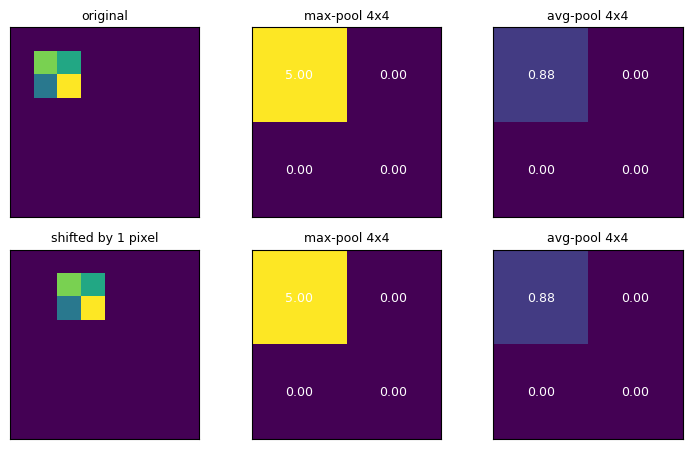

In [ ]:
toy_map = torch.zeros(1, 1, 8, 8)
toy_map[0, 0, 1:3, 1:3] = torch.tensor([[4.0, 3.0], [2.0, 5.0]])      # a bright spot in the top-left block
shifted_toy_map = torch.roll(toy_map, shifts=1, dims=3)                # same spot, one pixel to the right

max_pool = nn.MaxPool2d(4)
avg_pool = nn.AvgPool2d(4)

fig, axes = plt.subplots(2, 3, figsize=(7.5, 4.6))
for row, (name, feature_map) in enumerate([("original", toy_map), ("shifted by 1 pixel", shifted_toy_map)]):
    axes[row, 0].imshow(feature_map[0, 0], cmap="viridis", vmin=0, vmax=5)
    axes[row, 0].set_title(name, fontsize=9)
    for col, (pool_name, pool) in enumerate([("max-pool 4x4", max_pool), ("avg-pool 4x4", avg_pool)], start=1):
        pooled = pool(feature_map)[0, 0]
        axes[row, col].imshow(pooled, cmap="viridis", vmin=0, vmax=5)
        axes[row, col].set_title(pool_name, fontsize=9)
        for (r, c), value in np.ndenumerate(pooled.numpy()):
            axes[row, col].text(c, r, f"{value:.2f}", ha="center", va="center", color="white", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

The spot stays inside the same $4 \times 4$ block, so both pooled maps are identical for the original and the shifted map: the pooled output does not depend on where in the block the spot is. Max-pooling reports the strongest response (5), average pooling dilutes it with the zeros around it (0.88), which is why max-pooling is the usual choice for detecting whether a feature is present. Try `shifts=3`: the spot then crosses the block border and the pooled maps change, so the invariance holds only for shifts smaller than the window.

## Data

We reuse the cached $32 \times 32$ UTKFace images from the previous chapter (the cell below creates the cache if it is missing). The split is the same. Unlike before we standardize with **one** mean and standard deviation for all pixels, because a kernel is applied at every position and should see the same scale everywhere.

In [3]:
def build_cache():
    # Read the faces straight from the archive, convert to grayscale and shrink
    DATA_DIR.mkdir(exist_ok=True)
    if not ARCHIVE.exists():
        urllib.request.urlretrieve(ARCHIVE_URL, ARCHIVE)

    images, ages, genders = [], [], []
    with tarfile.open(ARCHIVE) as tar:
        for member in tar:
            if not (member.isfile() and member.name.endswith(".jpg")):
                continue
            fields = member.name.split("/")[-1].split("_")
            try:
                age, gender = int(fields[0]), int(fields[1])
            except ValueError:
                continue
            if gender not in (0, 1):
                continue
            image = Image.open(io.BytesIO(tar.extractfile(member).read()))
            image = image.convert("L").resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
            images.append(np.asarray(image, dtype=np.uint8))
            ages.append(age)
            genders.append(gender)
    np.savez_compressed(CACHE, images=np.stack(images), age=ages, gender=genders)

if not CACHE.exists():
    build_cache()

data = np.load(CACHE)
keep = data["age"] <= 80
images = data["images"][keep]          # (n, 32, 32), uint8
age = data["age"][keep]
female = data["gender"][keep].astype(np.float32)

idx_train, idx_rest = train_test_split(np.arange(len(age)), test_size=0.3, random_state=0, stratify=female)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.5, random_state=0, stratify=female[idx_rest])

pixels = images.astype(np.float32) / 255
pixel_mean, pixel_std = pixels[idx_train].mean(), pixels[idx_train].std()

def standardize_global(batch):
    # one mean and one standard deviation for all pixels; returns (n, 1, 32, 32)
    return torch.tensor((batch - pixel_mean) / pixel_std).unsqueeze(1)

X_cnn = standardize_global(pixels)
y_female = torch.tensor(female)
print("train / val / test:", len(idx_train), len(idx_val), len(idx_test))

train / val / test: 16217 3475 3476


## Training

We use the same training loop as before (mini-batches of 128, Adam, binary cross-entropy, keep the epoch with the best validation loss). Only 15 epochs are needed. The network class is defined first, then one instance with `N_KERNELS` kernels is created and trained.

In [4]:
def fit(model, X, target, n_epochs=15, learning_rate=3e-3, weight_decay=0.0, batch_size=128, seed=0):
    # Mini-batch Adam; returns the model with the best validation loss and the learning curves
    loss_fn = nn.BCEWithLogitsLoss()
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    X_train, y_train = X[idx_train], target[idx_train]
    X_val, y_val = X[idx_val], target[idx_val]

    history = {"train": [], "val": []}
    best_loss, best_state = float("inf"), None
    for epoch in range(n_epochs):
        model.train()
        order = torch.randperm(len(idx_train))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()
            loss_fn(model(X_train[batch]).squeeze(1), y_train[batch]).backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            history["train"].append(loss_fn(model(X_train).squeeze(1), y_train).item())
            history["val"].append(loss_fn(model(X_val).squeeze(1), y_val).item())
        if history["val"][-1] < best_loss:
            best_loss = history["val"][-1]
            best_state = {name: value.clone() for name, value in model.state_dict().items()}
            history["best_epoch"] = epoch

    model.load_state_dict(best_state)
    return model, history

def accuracy(model, X):
    model.eval()
    with torch.no_grad():
        return ((model(X).squeeze(1) > 0).float() == y_female[idx_test]).float().mean().item()

In [5]:
class TinyCNN(nn.Module):
    # one convolutional layer with n_kernels kernels, max-pooling and a linear output (the logit)
    def __init__(self, n_kernels=2, kernel_size=5, pool_size=4, image_size=IMAGE_SIZE):
        super().__init__()
        self.conv = nn.Conv2d(1, n_kernels, kernel_size, padding=kernel_size // 2)
        self.pool = nn.MaxPool2d(pool_size)
        self.output = nn.Linear(n_kernels * (image_size // pool_size) ** 2, 1)

    def feature_maps(self, x):
        # (n, 1, 32, 32) -> (n, n_kernels, 32, 32)
        return torch.relu(self.conv(x))

    def forward(self, x):
        pooled = self.pool(self.feature_maps(x))     # (n, n_kernels, 8, 8)
        return self.output(pooled.flatten(start_dim=1))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

parameters: 181


CNN test accuracy: 0.824


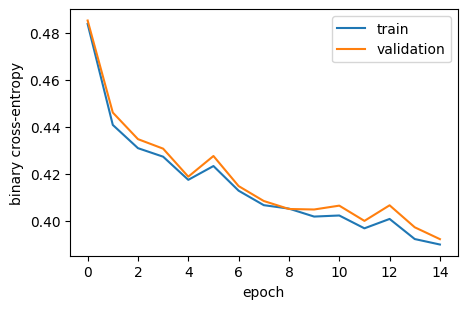

In [6]:
N_KERNELS = 2

torch.manual_seed(0)
cnn = TinyCNN(n_kernels=N_KERNELS)
initial_kernels = cnn.conv.weight.detach().clone()
print("parameters:", count_parameters(cnn))

cnn, hist_cnn = fit(cnn, X_cnn, y_female)
print(f"CNN test accuracy: {accuracy(cnn, X_cnn[idx_test]):.3f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(hist_cnn["train"], label="train")
ax.plot(hist_cnn["val"], label="validation")
ax.set(xlabel="epoch", ylabel="binary cross-entropy")
ax.legend()
plt.show()

For comparison we train the fully connected network of the previous chapter on the same split (with per-pixel standardization, as there).

In [7]:
X_flat = torch.tensor((pixels.reshape(len(pixels), -1) - pixels[idx_train].reshape(len(idx_train), -1).mean(0))
                      / (pixels[idx_train].reshape(len(idx_train), -1).std(0) + 1e-6))

torch.manual_seed(0)
ann = nn.Sequential(nn.Linear(1024, 64), nn.ReLU(), nn.Linear(64, 1))
ann, _ = fit(ann, X_flat, y_female, learning_rate=1e-3, weight_decay=1e-3, n_epochs=60)

print(f"ANN test accuracy (65,729 parameters): {accuracy(ann, X_flat[idx_test]):.3f}")
print(f"CNN test accuracy ({count_parameters(cnn)} parameters)    : {accuracy(cnn, X_cnn[idx_test]):.3f}")

ANN test accuracy (65,729 parameters): 0.871
CNN test accuracy (181 parameters)    : 0.824


## What Did the Kernels Learn?

Each kernel is a $5 \times 5$ image. We display the initial (random) and the learned kernels. Red weights increase and blue weights decrease the response of the kernel when the corresponding pixel of the patch is bright. A kernel responds most strongly to patches that look like itself, so it works as a small pattern detector: a kernel with a positive centre and negative surround detects bright spots, a kernel with positive top and negative bottom rows detects horizontal edges, and so on.

With only 2 kernels, 15 epochs and a $5 \times 5$ window on a $32 \times 32$ image, do not expect textbook edge detectors, and the kernels are far from perfectly clean. Still, they are not random noise: kernel 1 has large positive weights in its top row and negative weights below, so it responds to horizontal structures, while kernel 0 has a diagonal pattern of opposite signs.

Initial kernels


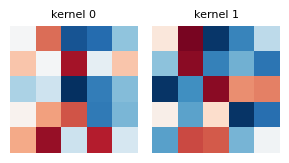

Learned kernels


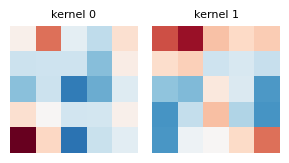

In [8]:
def show_kernels(kernels, titles):
    limit = kernels.abs().max().item()
    fig, axes = plt.subplots(1, len(kernels), figsize=(len(kernels) * 1.5, 1.9))
    for ax, kernel, title in zip(axes, kernels, titles):
        ax.imshow(kernel.squeeze(0), cmap="RdBu_r", vmin=-limit, vmax=limit)
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

learned_kernels = cnn.conv.weight.detach()
print("Initial kernels")
show_kernels(initial_kernels, [f"kernel {k}" for k in range(N_KERNELS)])
print("Learned kernels")
show_kernels(learned_kernels, [f"kernel {k}" for k in range(N_KERNELS)])

### Feature Maps

Applying a kernel to a face gives a feature map (after the ReLU): bright places are the positions where the pattern of the kernel was found. Below, each row is one test face and each column one of the feature maps (one per kernel).

With only two kernels the picture is easy to read. Kernel 1 lights up on horizontal dark-bright transitions: the eyebrows, the eyes and the mouth (teeth, lips). Kernel 0 mostly responds to the outline of the face and the hair line, which are mainly diagonal and vertical edges. These are the two kinds of information that the network combines for the decision.

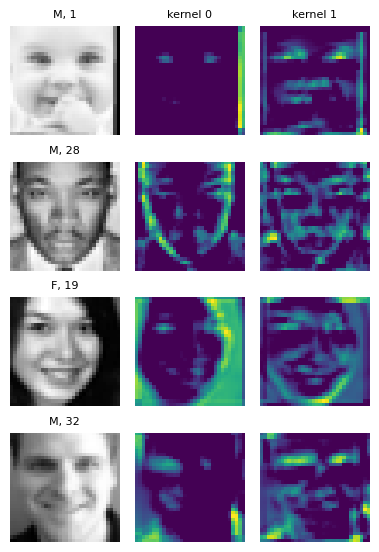

In [9]:
faces = idx_test[:4]
with torch.no_grad():
    feature_maps = cnn.feature_maps(X_cnn[faces])          # (4, N_KERNELS, 32, 32)

fig, axes = plt.subplots(len(faces), N_KERNELS + 1, figsize=((N_KERNELS + 1) * 1.3, len(faces) * 1.4))
for row, i in enumerate(faces):
    axes[row, 0].imshow(images[i], cmap="gray")
    axes[row, 0].set_title(f"{'F' if female[i] else 'M'}, {int(age[i])}", fontsize=8)
    for k in range(N_KERNELS):
        axes[row, k + 1].imshow(feature_maps[row, k], cmap="viridis")
        if row == 0:
            axes[row, k + 1].set_title(f"kernel {k}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

### Where Does the Output Layer Look?

The output layer has one weight for every channel and every position of the pooled $8 \times 8$ map ($64k$ weights). Reshaped, each channel gives an $8 \times 8$ image showing **where on the face** the presence of that kernel's pattern pushes the prediction towards female (red) or male (blue).

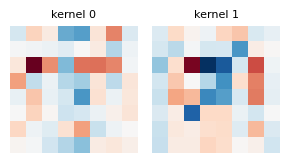

In [10]:
output_maps = cnn.output.weight.detach().reshape(N_KERNELS, 8, 8)
limit = output_maps.abs().max().item()
fig, axes = plt.subplots(1, N_KERNELS, figsize=(N_KERNELS * 1.5, 1.9))
for k, ax in enumerate(axes):
    ax.imshow(output_maps[k], cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(f"kernel {k}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Robustness to Shifts

We repeat the shift experiment of the previous chapter: all test images are shifted horizontally and both networks, trained only on centred faces, classify them.

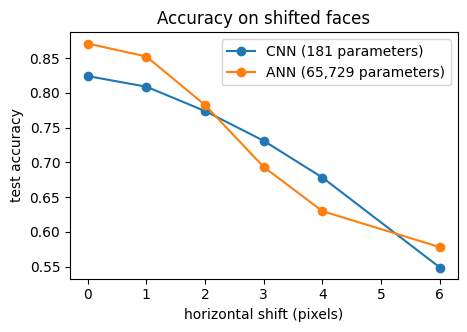

In [11]:
shifts = [0, 1, 2, 3, 4, 6]
ann_mean = pixels[idx_train].reshape(len(idx_train), -1).mean(0)
ann_std = pixels[idx_train].reshape(len(idx_train), -1).std(0) + 1e-6

cnn_accuracy, ann_accuracy = [], []
for shift in shifts:
    shifted = np.roll(pixels[idx_test], shift, axis=2)
    cnn_accuracy.append(accuracy(cnn, standardize_global(shifted)))
    flat = (shifted.reshape(len(idx_test), -1) - ann_mean) / ann_std
    ann_accuracy.append(accuracy(ann, torch.tensor(flat)))

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(shifts, cnn_accuracy, marker="o", label=f"CNN ({count_parameters(cnn)} parameters)")
ax.plot(shifts, ann_accuracy, marker="o", label="ANN (65,729 parameters)")
ax.set(xlabel="horizontal shift (pixels)", ylabel="test accuracy", title="Accuracy on shifted faces")
ax.legend()
plt.show()

## Summary

- A convolutional layer reuses a small kernel at all positions: 52 parameters in the convolution (for $k = 2$) instead of $1024 \cdot 64$ in the hidden layer of the fully connected network.
- The learned kernels are small pattern detectors and their feature maps show where on the face the patterns occur.
- With two kernels and 181 parameters the CNN reaches about 82% test accuracy (the fully connected network: 87%). Accuracy was not the goal; adding kernels (exercise 1) closes most of the gap.
- Weight sharing and max-pooling make the CNN somewhat less sensitive to shifts of the face: for shifts of 3-4 pixels it is about 4-5 percentage points more accurate than the fully connected network, but with a shift of 6 pixels both are close to the majority-class level. The network was never trained on shifted faces and has only one small convolutional layer.
- Real image models stack many such layers; the idea is the same.

## Exercises

1. Change `N_KERNELS` (1, 4, 8, 16) and the kernel size (3, 7). How does the test accuracy change? Do the kernels stay interpretable?
2. Remove the max-pooling (the linear layer then needs $32 \cdot 32 \cdot k$ inputs; change `pool_size` to 1). What happens to the number of parameters and to the shift robustness?
3. Train the same network for age (linear output, squared error) and compare its kernels with the gender kernels.